# M14 – Phân tích và trực quan hóa BERTopic

Notebook này dùng để trình bày kết quả đã được tạo bởi pipeline M13–M14. Notebook **không huấn luyện lại mô hình** mà đọc các artifact đã xuất, nhờ đó chạy nhanh và không làm thay đổi kết quả thí nghiệm.

Mục tiêu:
- giải thích luồng xử lý từ embedding đến topic;
- so sánh các cấu hình E0–E3;
- quan sát cụm trên bản đồ embedding 2D;
- giải thích topic bằng c-TF-IDF;
- kiểm tra bài báo được gán vào từng topic.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_columns", 20)

ROOT = Path.cwd()
if not (ROOT / "results").exists():
    ROOT = ROOT.parent

RESULT_DIR = ROOT / "results" / "bertopic_experiments"
E1_DIR = RESULT_DIR / "e1_vietnamese_sbert"
FIGURE_DIR = ROOT / "results" / "bertopic_visualization"

print(f"Project root: {ROOT}")

Project root: c:\Users\Ngan\Documents\NLP\vietnamese-news-topic-discovery


## 1. Đọc các artifact

Các bảng dưới đây là đầu ra có thể kiểm tra lại của pipeline, thay vì chỉ lưu mô hình hoặc ảnh.

In [2]:
summary = pd.read_csv(RESULT_DIR / "summary.csv", encoding="utf-8-sig")
topic_summary = pd.read_csv(E1_DIR / "topic_summary.csv", encoding="utf-8-sig")
topic_keywords = pd.read_csv(E1_DIR / "topic_keywords.csv", encoding="utf-8-sig")
document_topics = pd.read_csv(E1_DIR / "document_topics.csv", encoding="utf-8-sig")
embedding_projection = pd.read_csv(E1_DIR / "embedding_projection.csv", encoding="utf-8-sig")

print(f"Số cấu hình: {len(summary)}")
print(f"Số topic E1: {len(topic_summary)}")
print(f"Số bài có topic assignment: {len(document_topics):,}")
print(f"Số điểm trên bản đồ 2D: {len(embedding_projection):,}")

Số cấu hình: 4
Số topic E1: 96
Số bài có topic assignment: 7,884
Số điểm trên bản đồ 2D: 7,884


## 2. Pipeline BERTopic

1. Dữ liệu đã đóng băng được ghép thành văn bản đầu vào.
2. Vietnamese SBERT chuyển văn bản thành embedding ngữ nghĩa.
3. UMAP giảm chiều để hỗ trợ phân cụm.
4. HDBSCAN tạo cụm và đánh dấu outlier bằng topic `-1`.
5. c-TF-IDF tìm từ khóa đặc trưng để giải thích từng topic.

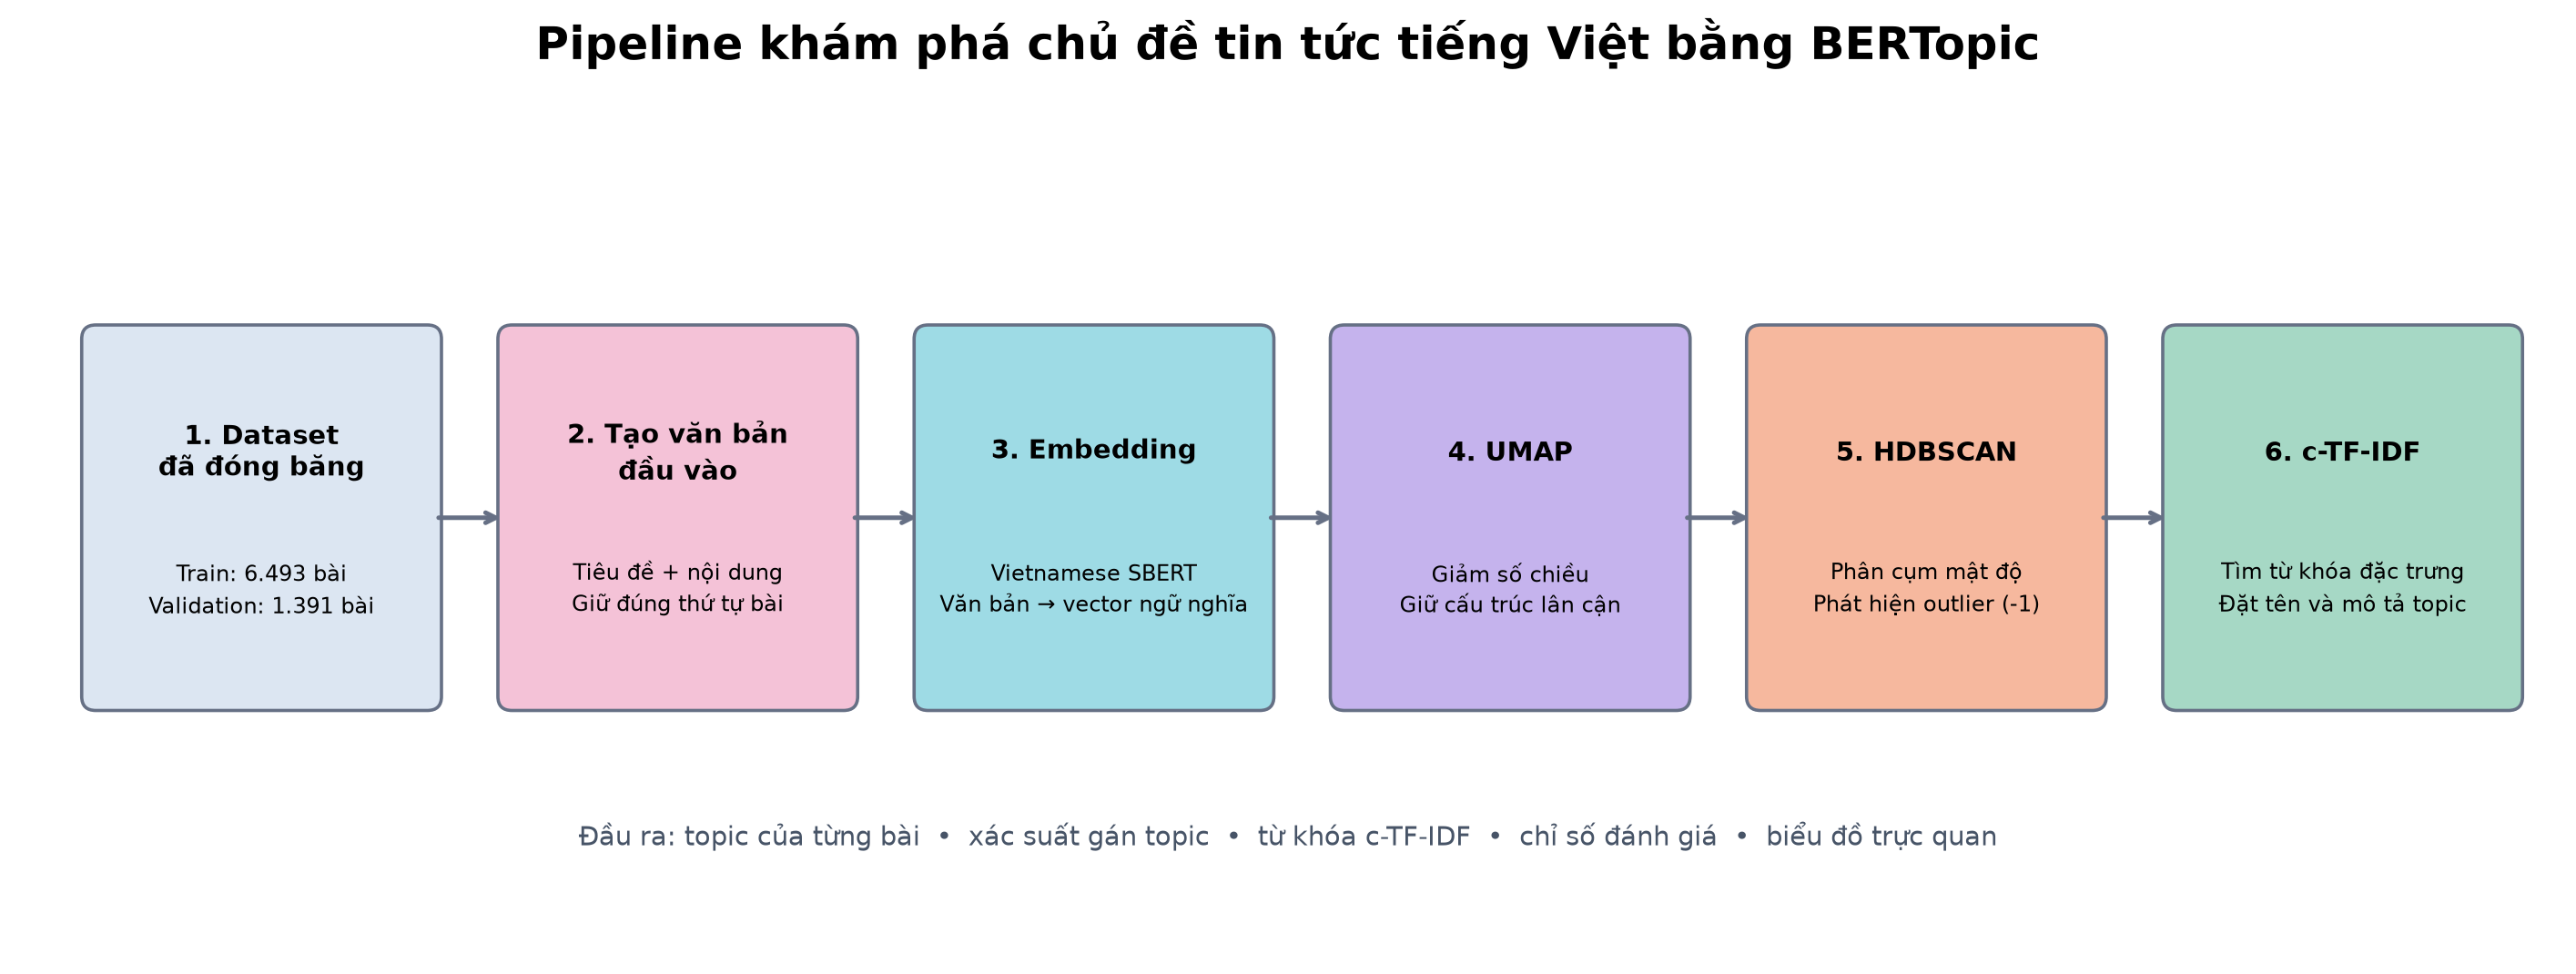

In [3]:
display(Image(filename=str(FIGURE_DIR / "07_bertopic_pipeline.png")))

## 3. So sánh E0–E3

E1 được dùng để phân tích sâu vì có tỷ lệ outlier thấp nhất trên cả train và validation. Điều này không có nghĩa E1 tốt nhất ở mọi chỉ số: E3 có topic diversity cao hơn, còn E0 chạy nhanh hơn.

In [4]:
comparison = summary[[
    "run_id",
    "topic_count",
    "train_outlier_rate",
    "validation_outlier_rate",
    "topic_diversity",
    "runtime_seconds",
]].copy()

comparison["run_id"] = comparison["run_id"].str.split("_").str[0].str.upper()
comparison = comparison.sort_values("run_id")
comparison.style.format({
    "train_outlier_rate": "{:.1%}",
    "validation_outlier_rate": "{:.1%}",
    "topic_diversity": "{:.3f}",
    "runtime_seconds": "{:.1f} giây",
}).background_gradient(subset=["validation_outlier_rate"], cmap="RdPu")

,run_id,topic_count,train_outlier_rate,validation_outlier_rate,topic_diversity,runtime_seconds
0,E0,111,31.1%,42.3%,0.700,183.3 giây
3,E1,96,24.6%,35.9%,0.681,1159.7 giây
1,E2,93,33.6%,51.9%,0.698,905.4 giây
2,E3,57,29.6%,39.1%,0.746,997.9 giây


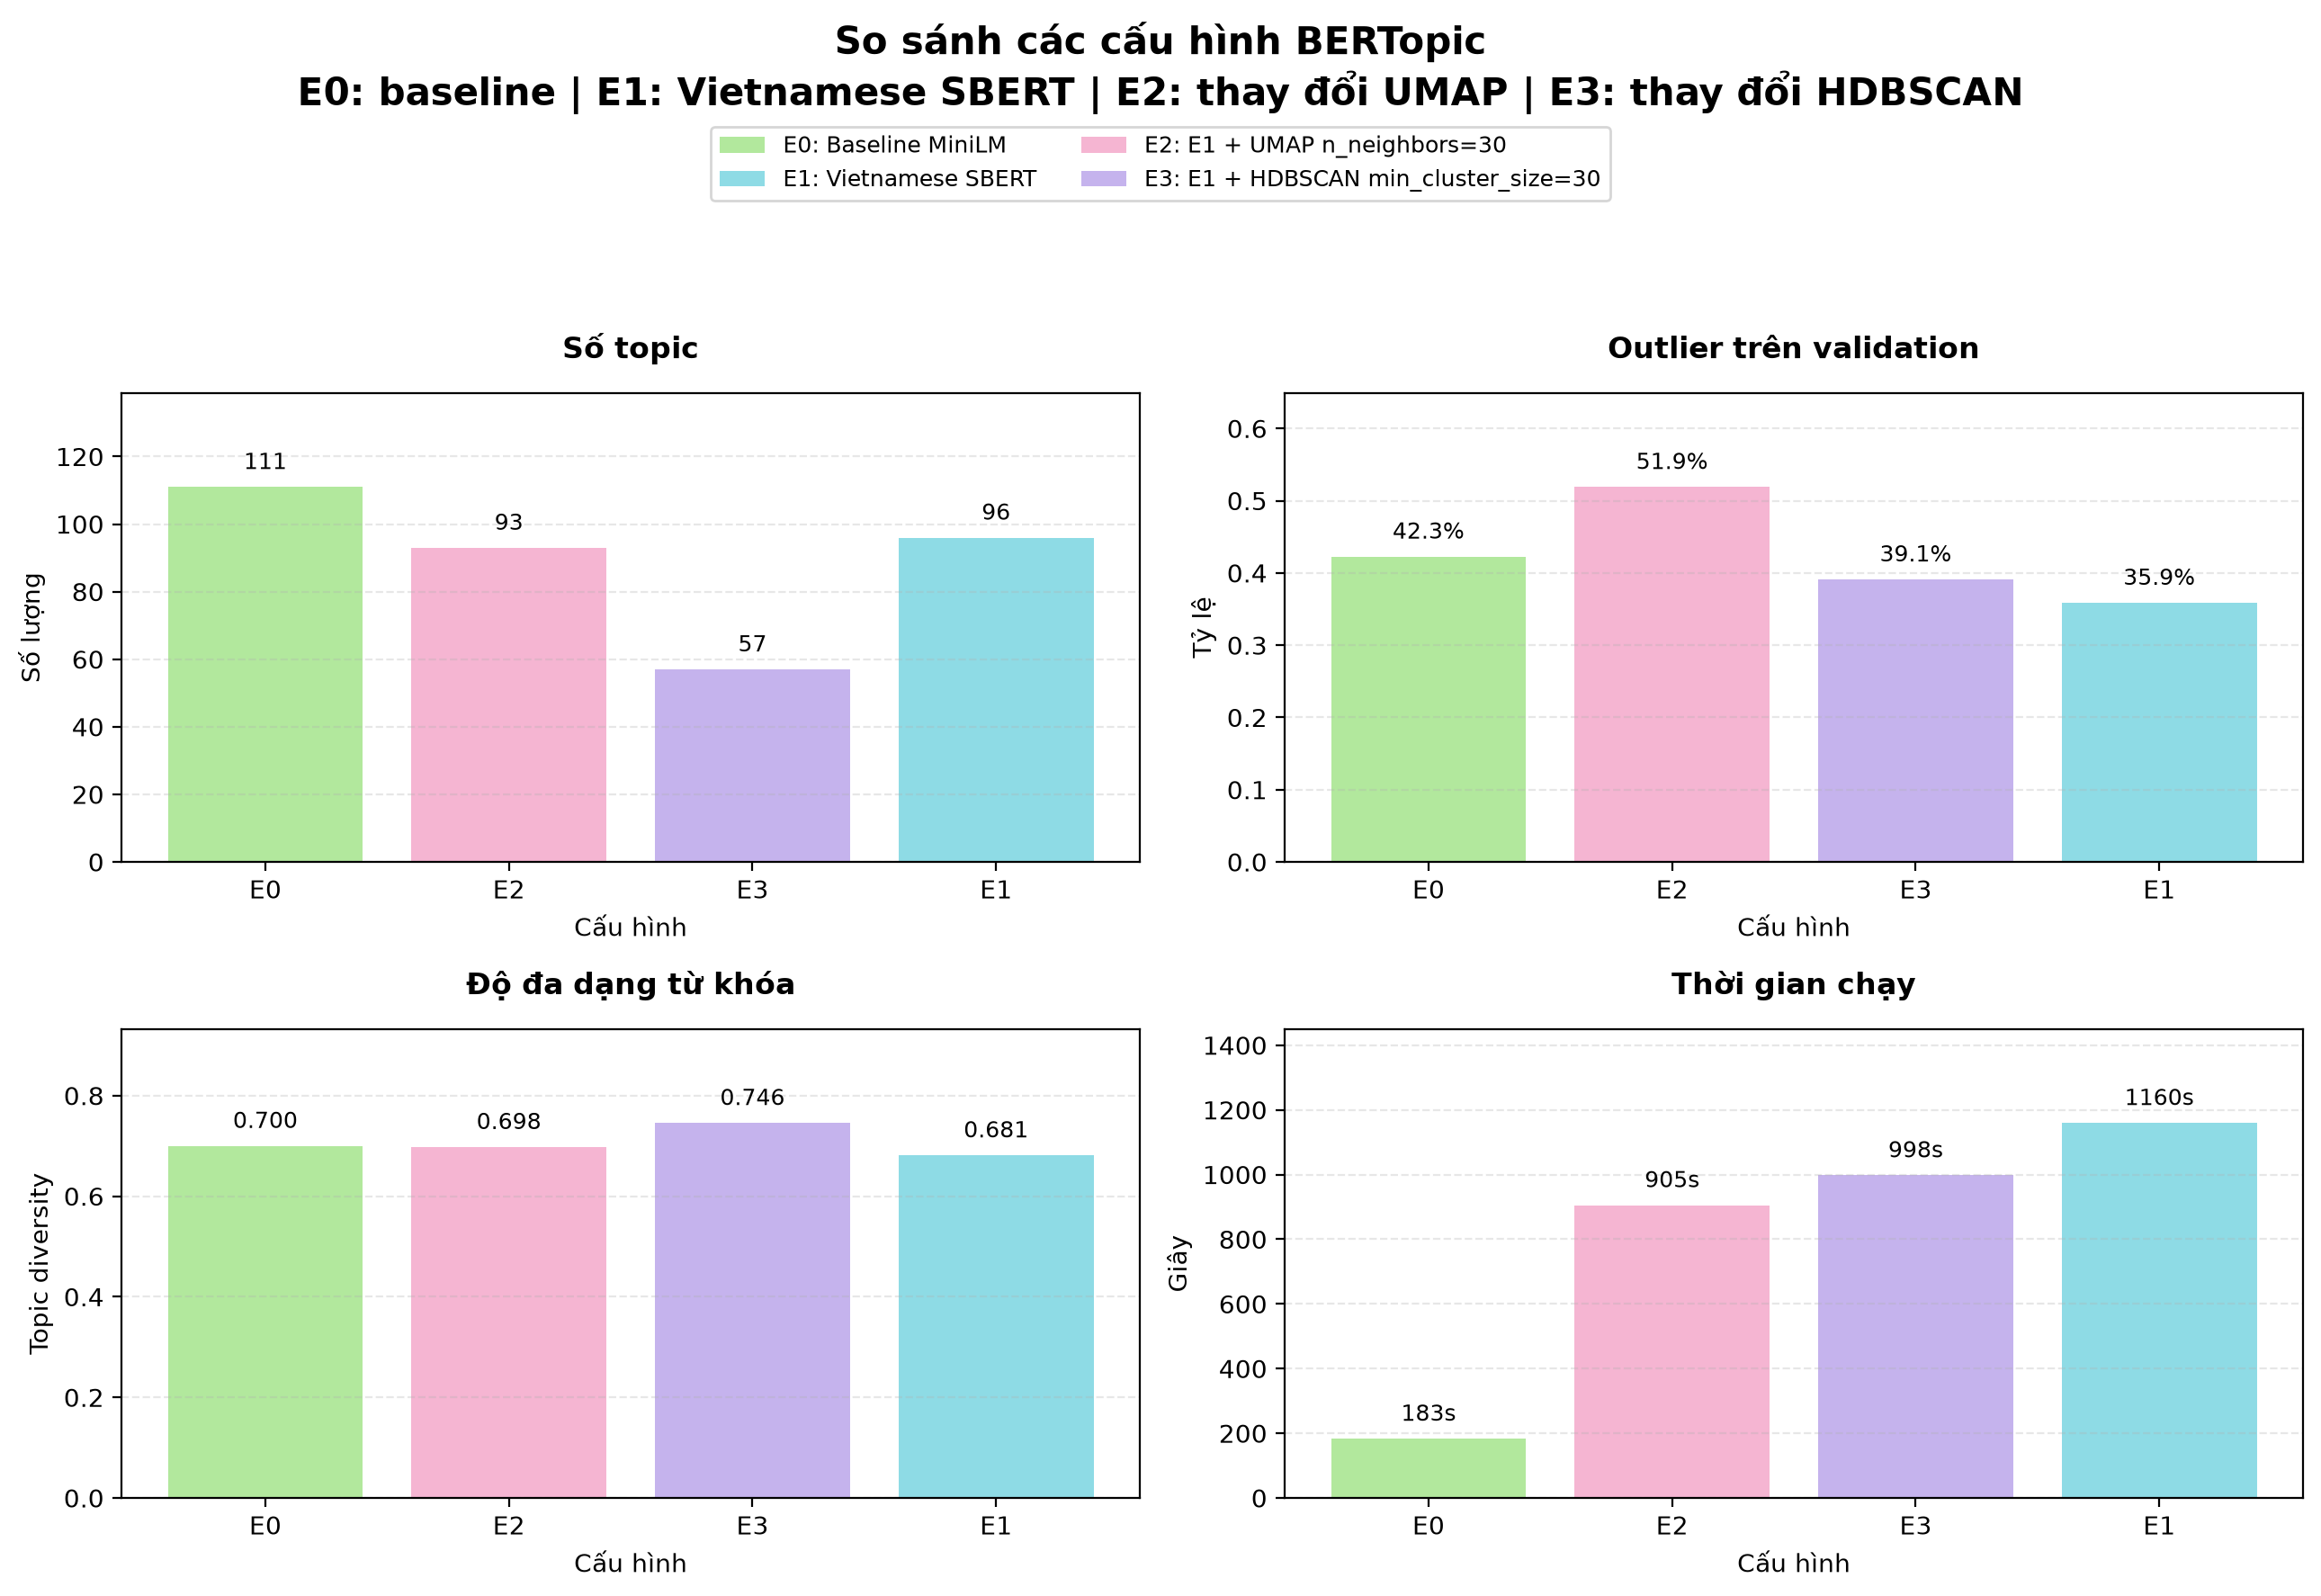

In [5]:
display(Image(filename=str(FIGURE_DIR / "01_experiment_dashboard.png")))

## 4. Các topic lớn của E1

Bảng cho biết kích thước, từ khóa, tiêu đề đại diện, nhãn chi phối và độ thuần theo nhãn tham chiếu. Nhãn chỉ dùng để diễn giải sau phân cụm, không được dùng để huấn luyện BERTopic.

In [6]:
topic_summary[[
    "topic",
    "topic_name",
    "document_count",
    "percentage",
    "top_keywords",
    "dominant_category",
    "category_purity",
]].head(15).style.format({
    "percentage": "{:.2%}",
    "category_purity": "{:.2%}",
})

,topic,topic_name,document_count,percentage,top_keywords,dominant_category,category_purity
0,0,0_doanh_doanh nghiệp_phát triển,462,7.12%,"doanh, doanh nghiệp, phát triển, sản, việt nam",Kinh doanh,76.84%
1,1,1_cáo_tội_điều tra,299,4.60%,"cáo, tội, điều tra, tra, công an",Pháp luật,93.31%
2,2,2_ăn_uống_cơ thể,200,3.08%,"ăn, uống, cơ thể, thực phẩm, béo",Sức khỏe,94.00%
3,3,3_iphone_pro_apple,165,2.54%,"iphone, pro, apple, 18 pro, iphone 18",Khoa học công nghệ,90.91%
4,4,4_bệnh_bệnh viện_viện,137,2.11%,"bệnh, bệnh viện, viện, khám, thuốc",Sức khỏe,91.24%
5,5,5_asiad_vđv_nữ,119,1.83%,"asiad, vđv, nữ, nội dung, dung",Thể thao,99.16%
6,6,6_nhạc_ca_âm,109,1.68%,"nhạc, ca, âm, âm nhạc, hát",Giải trí,82.57%
7,7,7_đức anh_công an_đức,101,1.56%,"đức anh, công an, đức, vợ, dao",Pháp luật,100.00%
8,8,8_học sinh_trú_giáo,91,1.40%,"học sinh, trú, giáo, lớp, tiểu học",Giáo dục,96.70%
9,9,9_openai_anthropic_mô hình,88,1.36%,"openai, anthropic, mô hình, mô, ceo",Khoa học công nghệ,86.36%


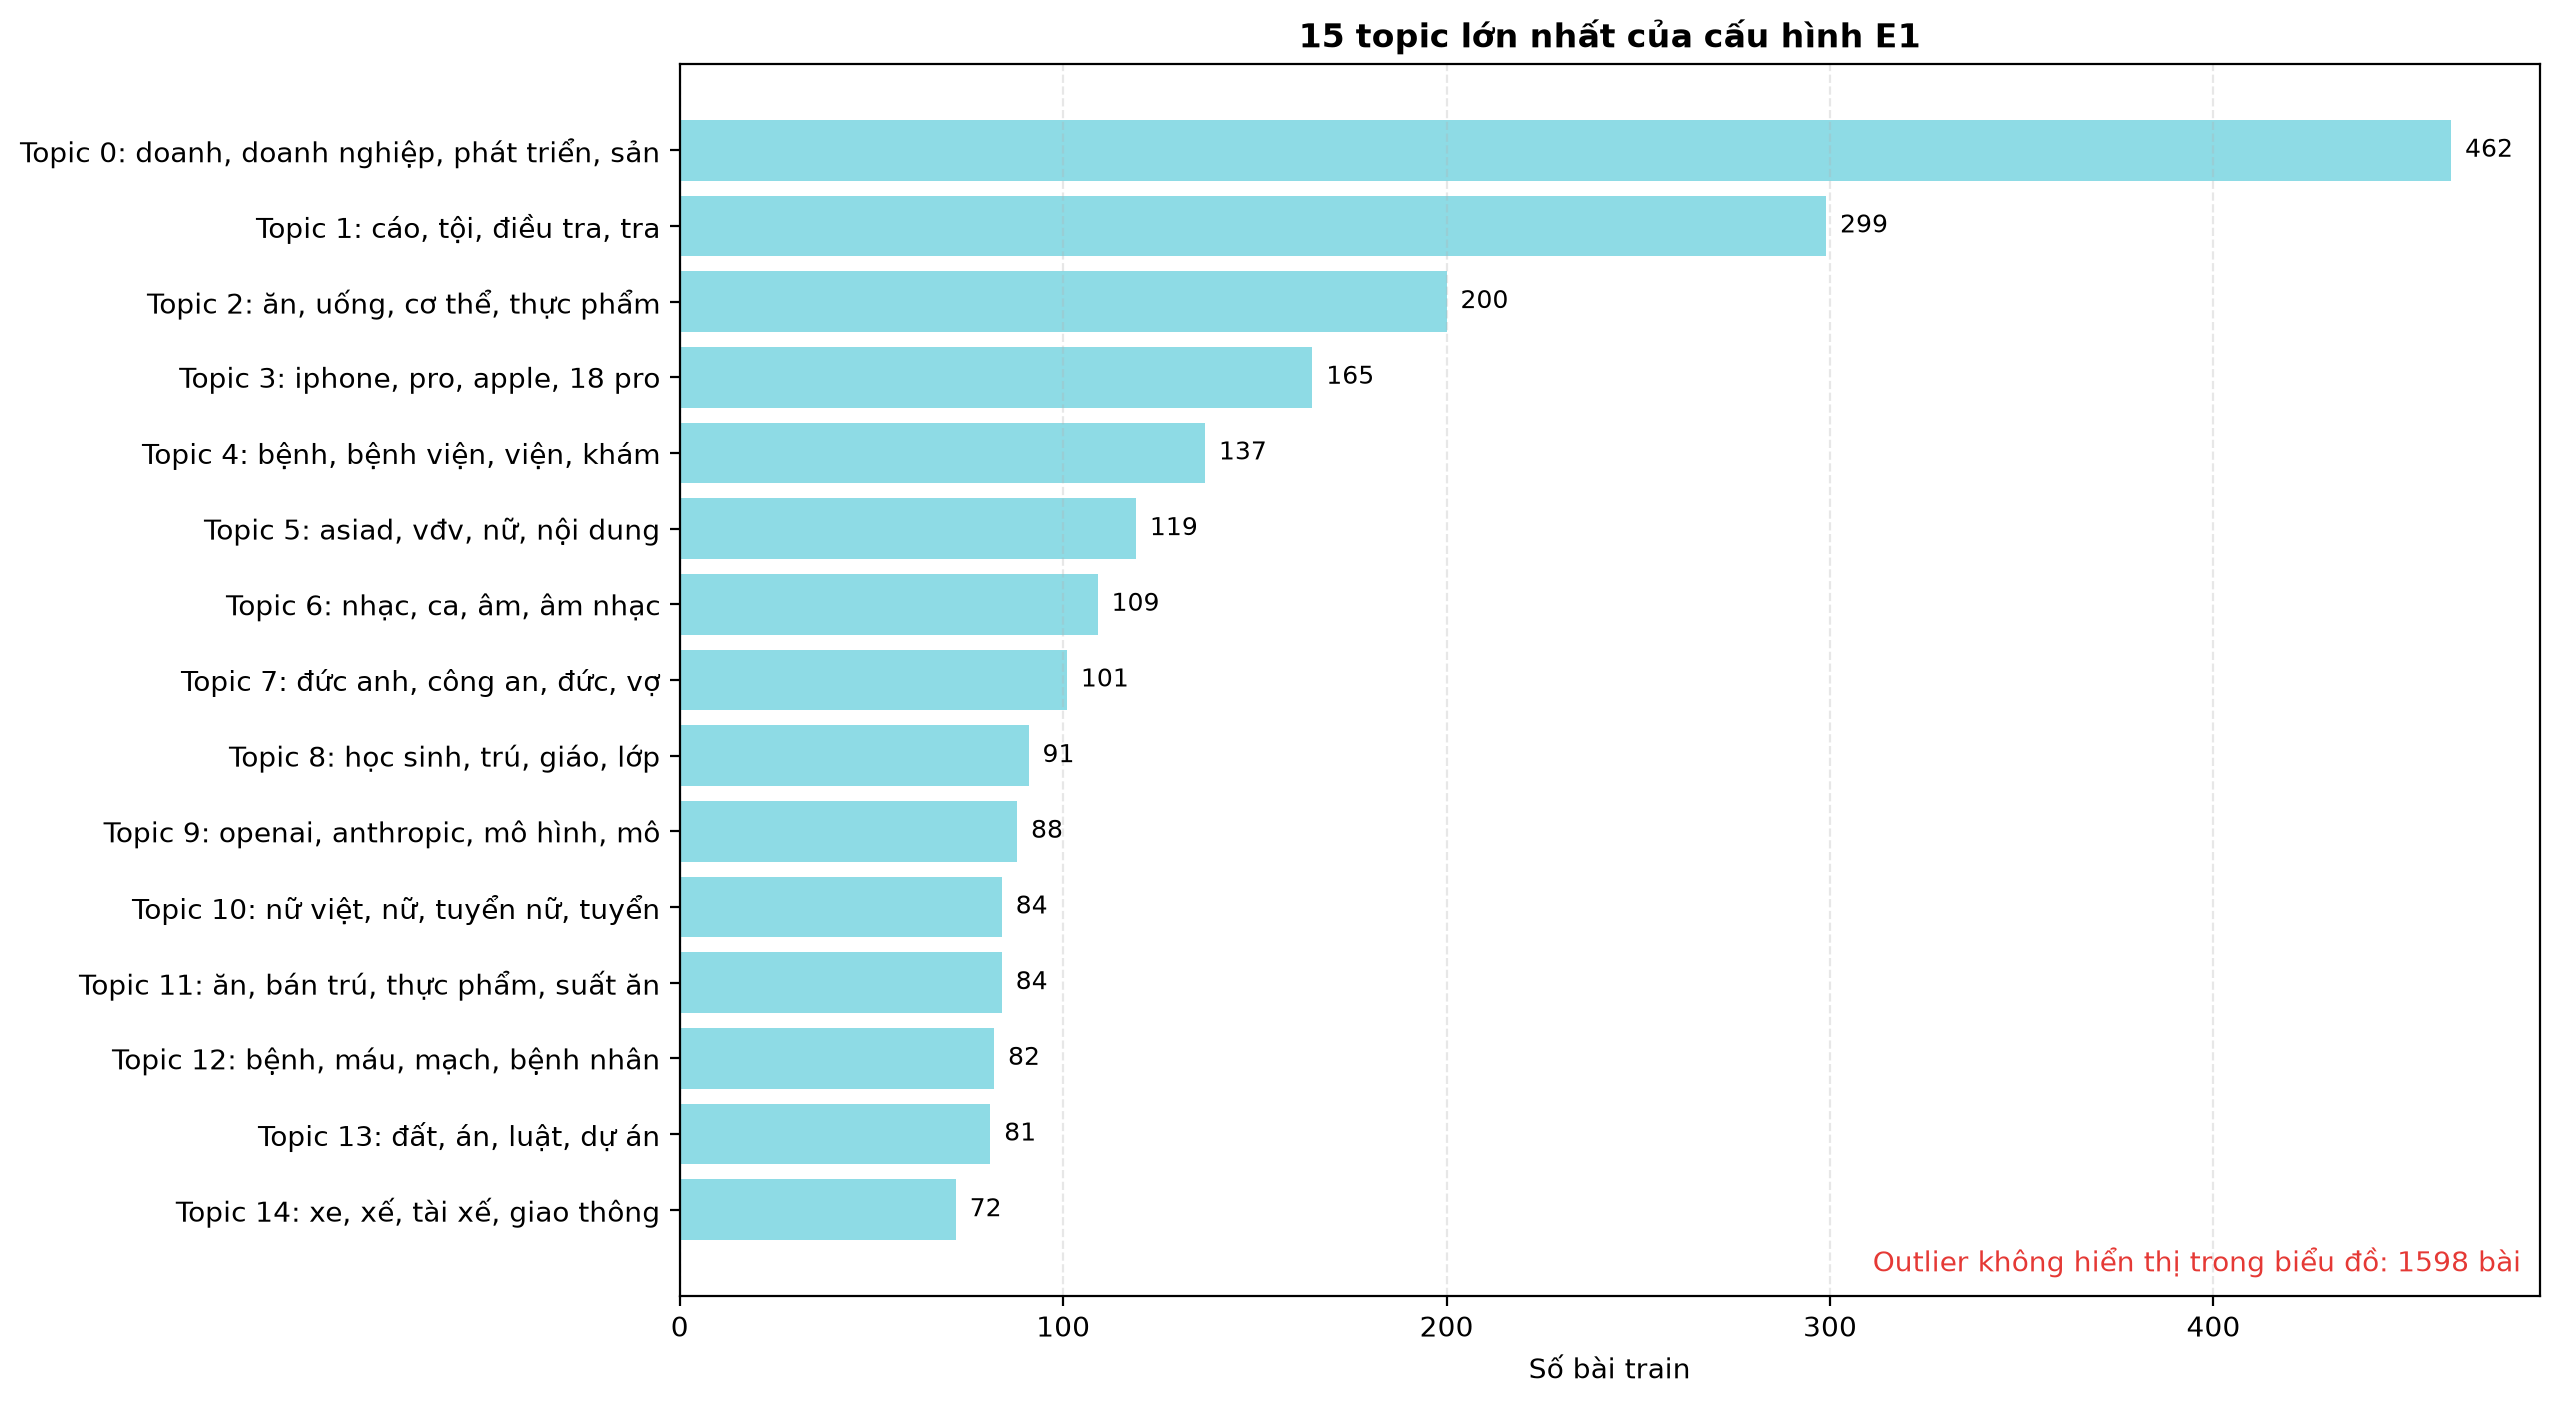

In [7]:
display(Image(filename=str(FIGURE_DIR / "04_e1_topic_sizes.png")))

## 5. Bản đồ embedding 2D

Mỗi điểm là một bài báo. Điểm gần nhau có embedding ngữ nghĩa tương tự; màu là topic; dấu `x` là outlier HDBSCAN. UMAP 2D chỉ phục vụ trực quan hóa nên không nên dùng hình này như bằng chứng duy nhất về chất lượng cụm.

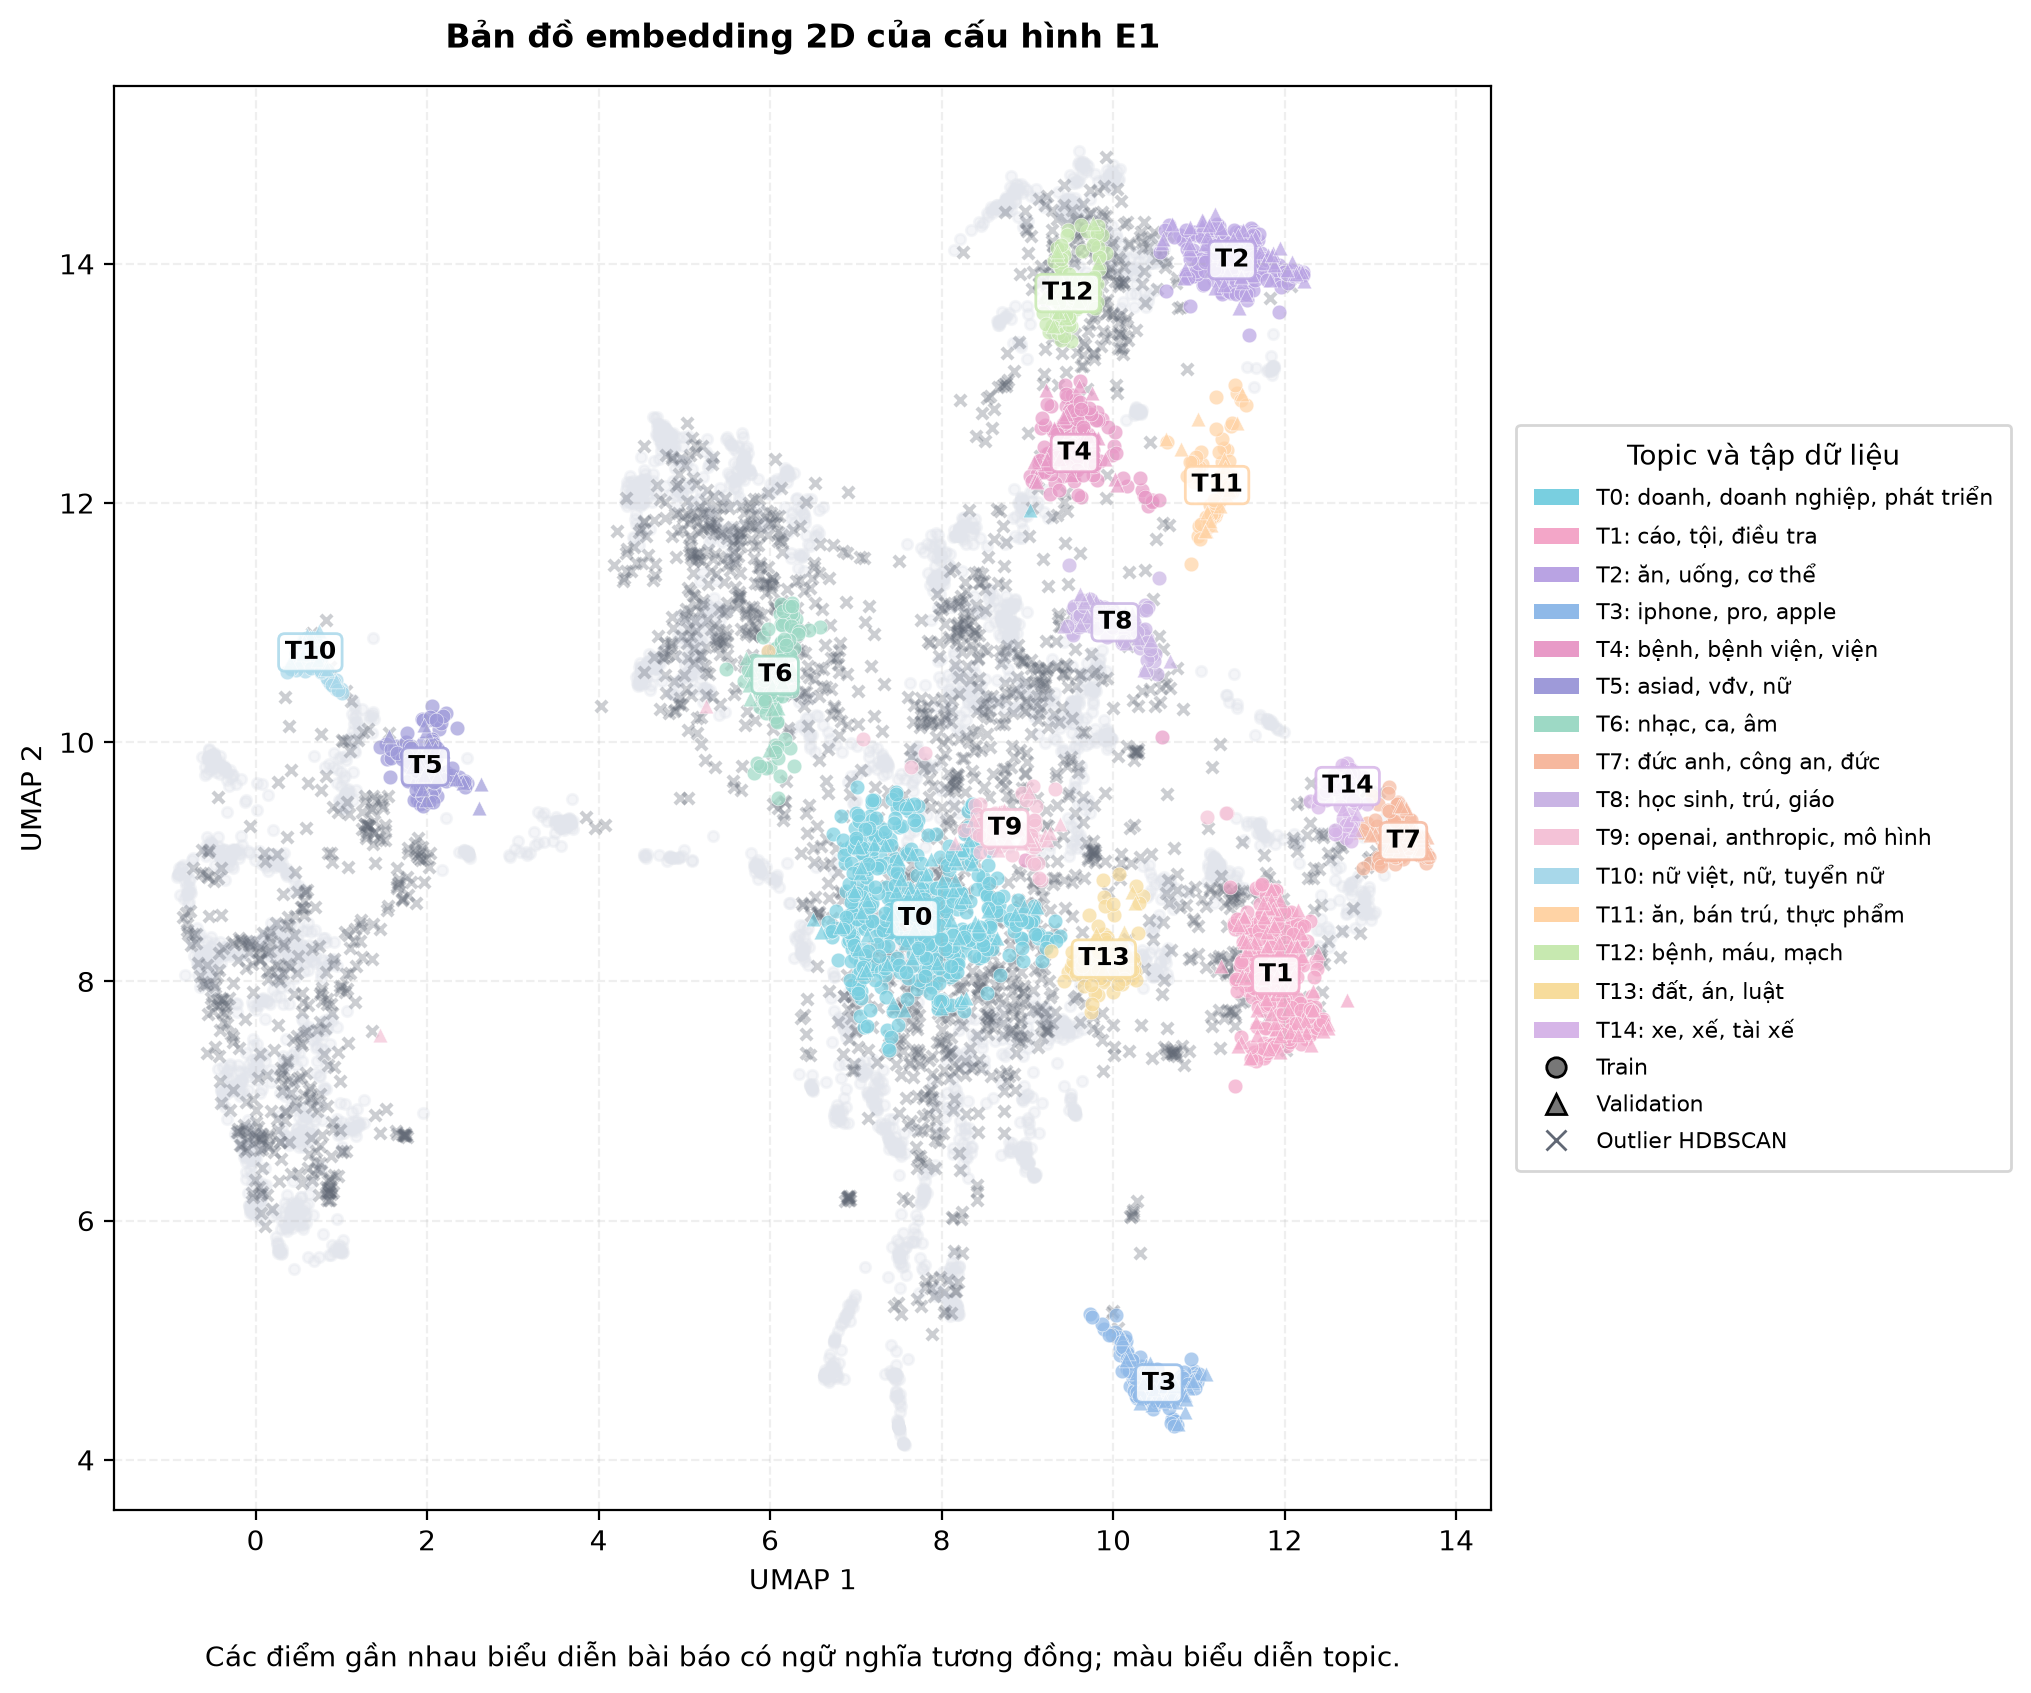

In [8]:
display(Image(filename=str(FIGURE_DIR / "05_e1_embedding_map.png")))

## 6. Giải thích topic bằng c-TF-IDF

Điểm c-TF-IDF cao cho biết một từ nổi bật trong topic nhưng ít phổ biến ở các topic khác. Đây là lớp giải thích nội dung cụm sau HDBSCAN.

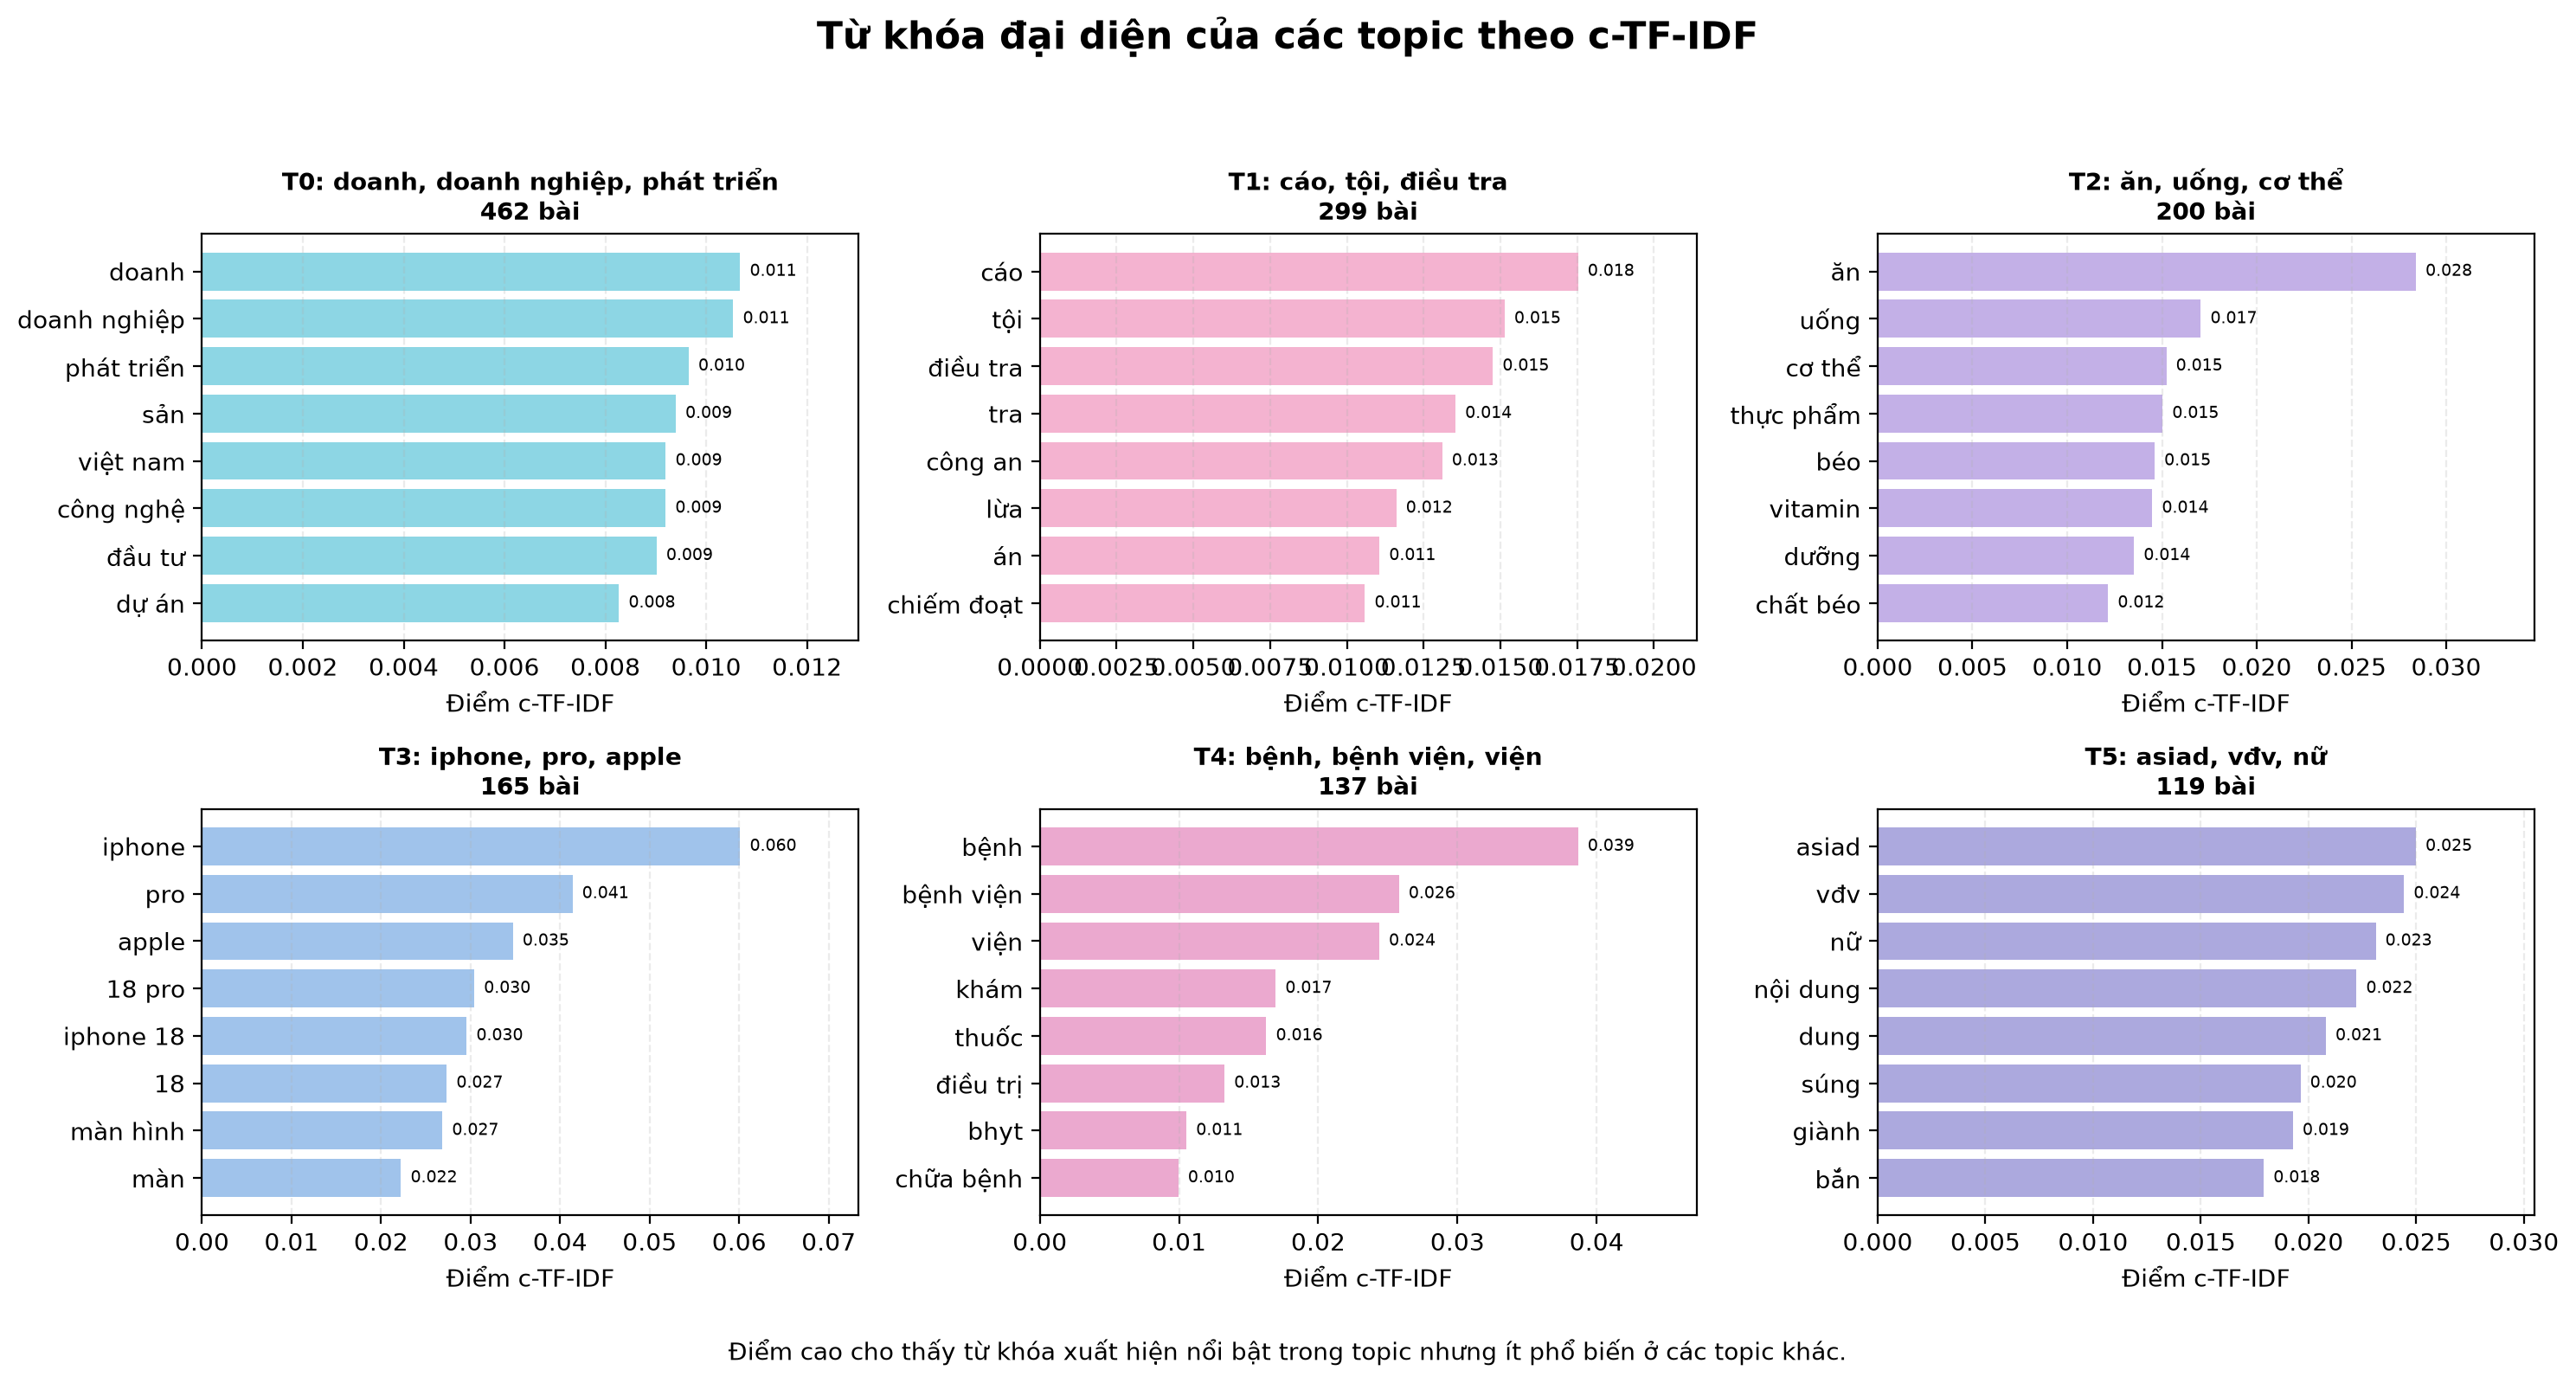

In [9]:
display(Image(filename=str(FIGURE_DIR / "06_e1_ctfidf_keywords.png")))

## 7. Tra cứu một topic cụ thể

Đổi `SELECTED_TOPIC` để xem từ khóa và các bài có xác suất gán cao nhất trong topic mong muốn.

In [10]:
SELECTED_TOPIC = 3

selected_summary = topic_summary.loc[
    topic_summary["topic"] == SELECTED_TOPIC
]
selected_keywords = topic_keywords.loc[
    topic_keywords["topic"] == SELECTED_TOPIC
].sort_values("rank").head(10)

display(selected_summary)
display(selected_keywords[["rank", "word", "ctfidf_score"]])

,topic,topic_name,document_count,percentage,top_keywords,representative_titles,dominant_category,category_purity
3,3,3_iphone_pro_apple,165,0.025412,"iphone, pro, apple, 18 pro, iphone 18",Thị trường chùng xuống chờ iPhone 18 ra mắt | Những thông tin rò rỉ về iPhone 18 màn hình gập | Trung Quốc chế tạo m...,Khoa học công nghệ,0.909091


,rank,word,ctfidf_score
30,1,iphone,0.060114
31,2,pro,0.041383
32,3,apple,0.034727
33,4,18 pro,0.030413
34,5,iphone 18,0.029566
35,6,18,0.027338
36,7,màn hình,0.026852
37,8,màn,0.022228
38,9,max,0.021141
39,10,pro max,0.020700


In [11]:
selected_documents = (
    document_topics.loc[document_topics["topic"] == SELECTED_TOPIC]
    .sort_values("topic_probability", ascending=False)
)

columns = [
    column
    for column in ["article_id", "split", "topic_probability", "title"]
    if column in selected_documents.columns
]
selected_documents[columns].head(10)

,article_id,split,topic_probability,title
316,TTR_207368b3e867,train,1.0,Những thông tin rò rỉ về iPhone 18 màn hình gập
377,TTR_273e1d301406,train,1.0,"Trung Quốc chế tạo máy CT 'cỡ lòng bàn tay', nặng chỉ 6kg"
455,TTR_2e70edee952f,train,1.0,"iPhone 18 chưa lên kệ, phụ kiện đã ‘đua’ ra mắt rầm rộ"
568,TTR_3a35e7cc91a1,train,1.0,"Hàng chục ngàn iPhone 18 đã đến tay khách Việt chỉ sau 3 ngày, màu máy nào áp đảo?"
1245,TTR_78b52aac827d,train,1.0,Quan tâm iPhone Duo nhưng nhiều người Việt muốn mua iPhone 18 Pro Max
1042,TTR_6320fa94d3e2,train,1.0,"Giá bán iPhone 18 Pro, Pro Max và iPhone Duo tại Việt Nam: Bản cao nhất vượt mốc 100 triệu đồng"
1323,TTR_7f1d531a367a,train,1.0,Chạm giá 2.000 USD: iPhone Duo đắt gần gấp đôi nhưng nhiều cái còn thua iPhone 18 pro max?
1725,TTR_a4e451856e8c,train,1.0,Nhà bán lẻ tất bật trước giờ G mở bán iPhone 18 tại Việt Nam
4624,VNE_f1dd9b93a2f7,train,1.0,Công nghệ màng carbon lỏng giúp sản xuất chip 3D phức tạp
1875,TTR_b3903c3caa9b,train,1.0,"Cuộc đua smartphone cuối năm: Camera tự xoay, pin 'khủng' 10.000mAh"


## 8. Đánh giá độ cân bằng và độ rõ của cụm

Dashboard kết hợp phân phối kích thước topic, các topic lớn nhất, xác suất gán topic và tỷ lệ outlier theo split. Validation có outlier cao hơn train, cho thấy cấu trúc cụm chưa bao phủ hoàn toàn dữ liệu chưa thấy.

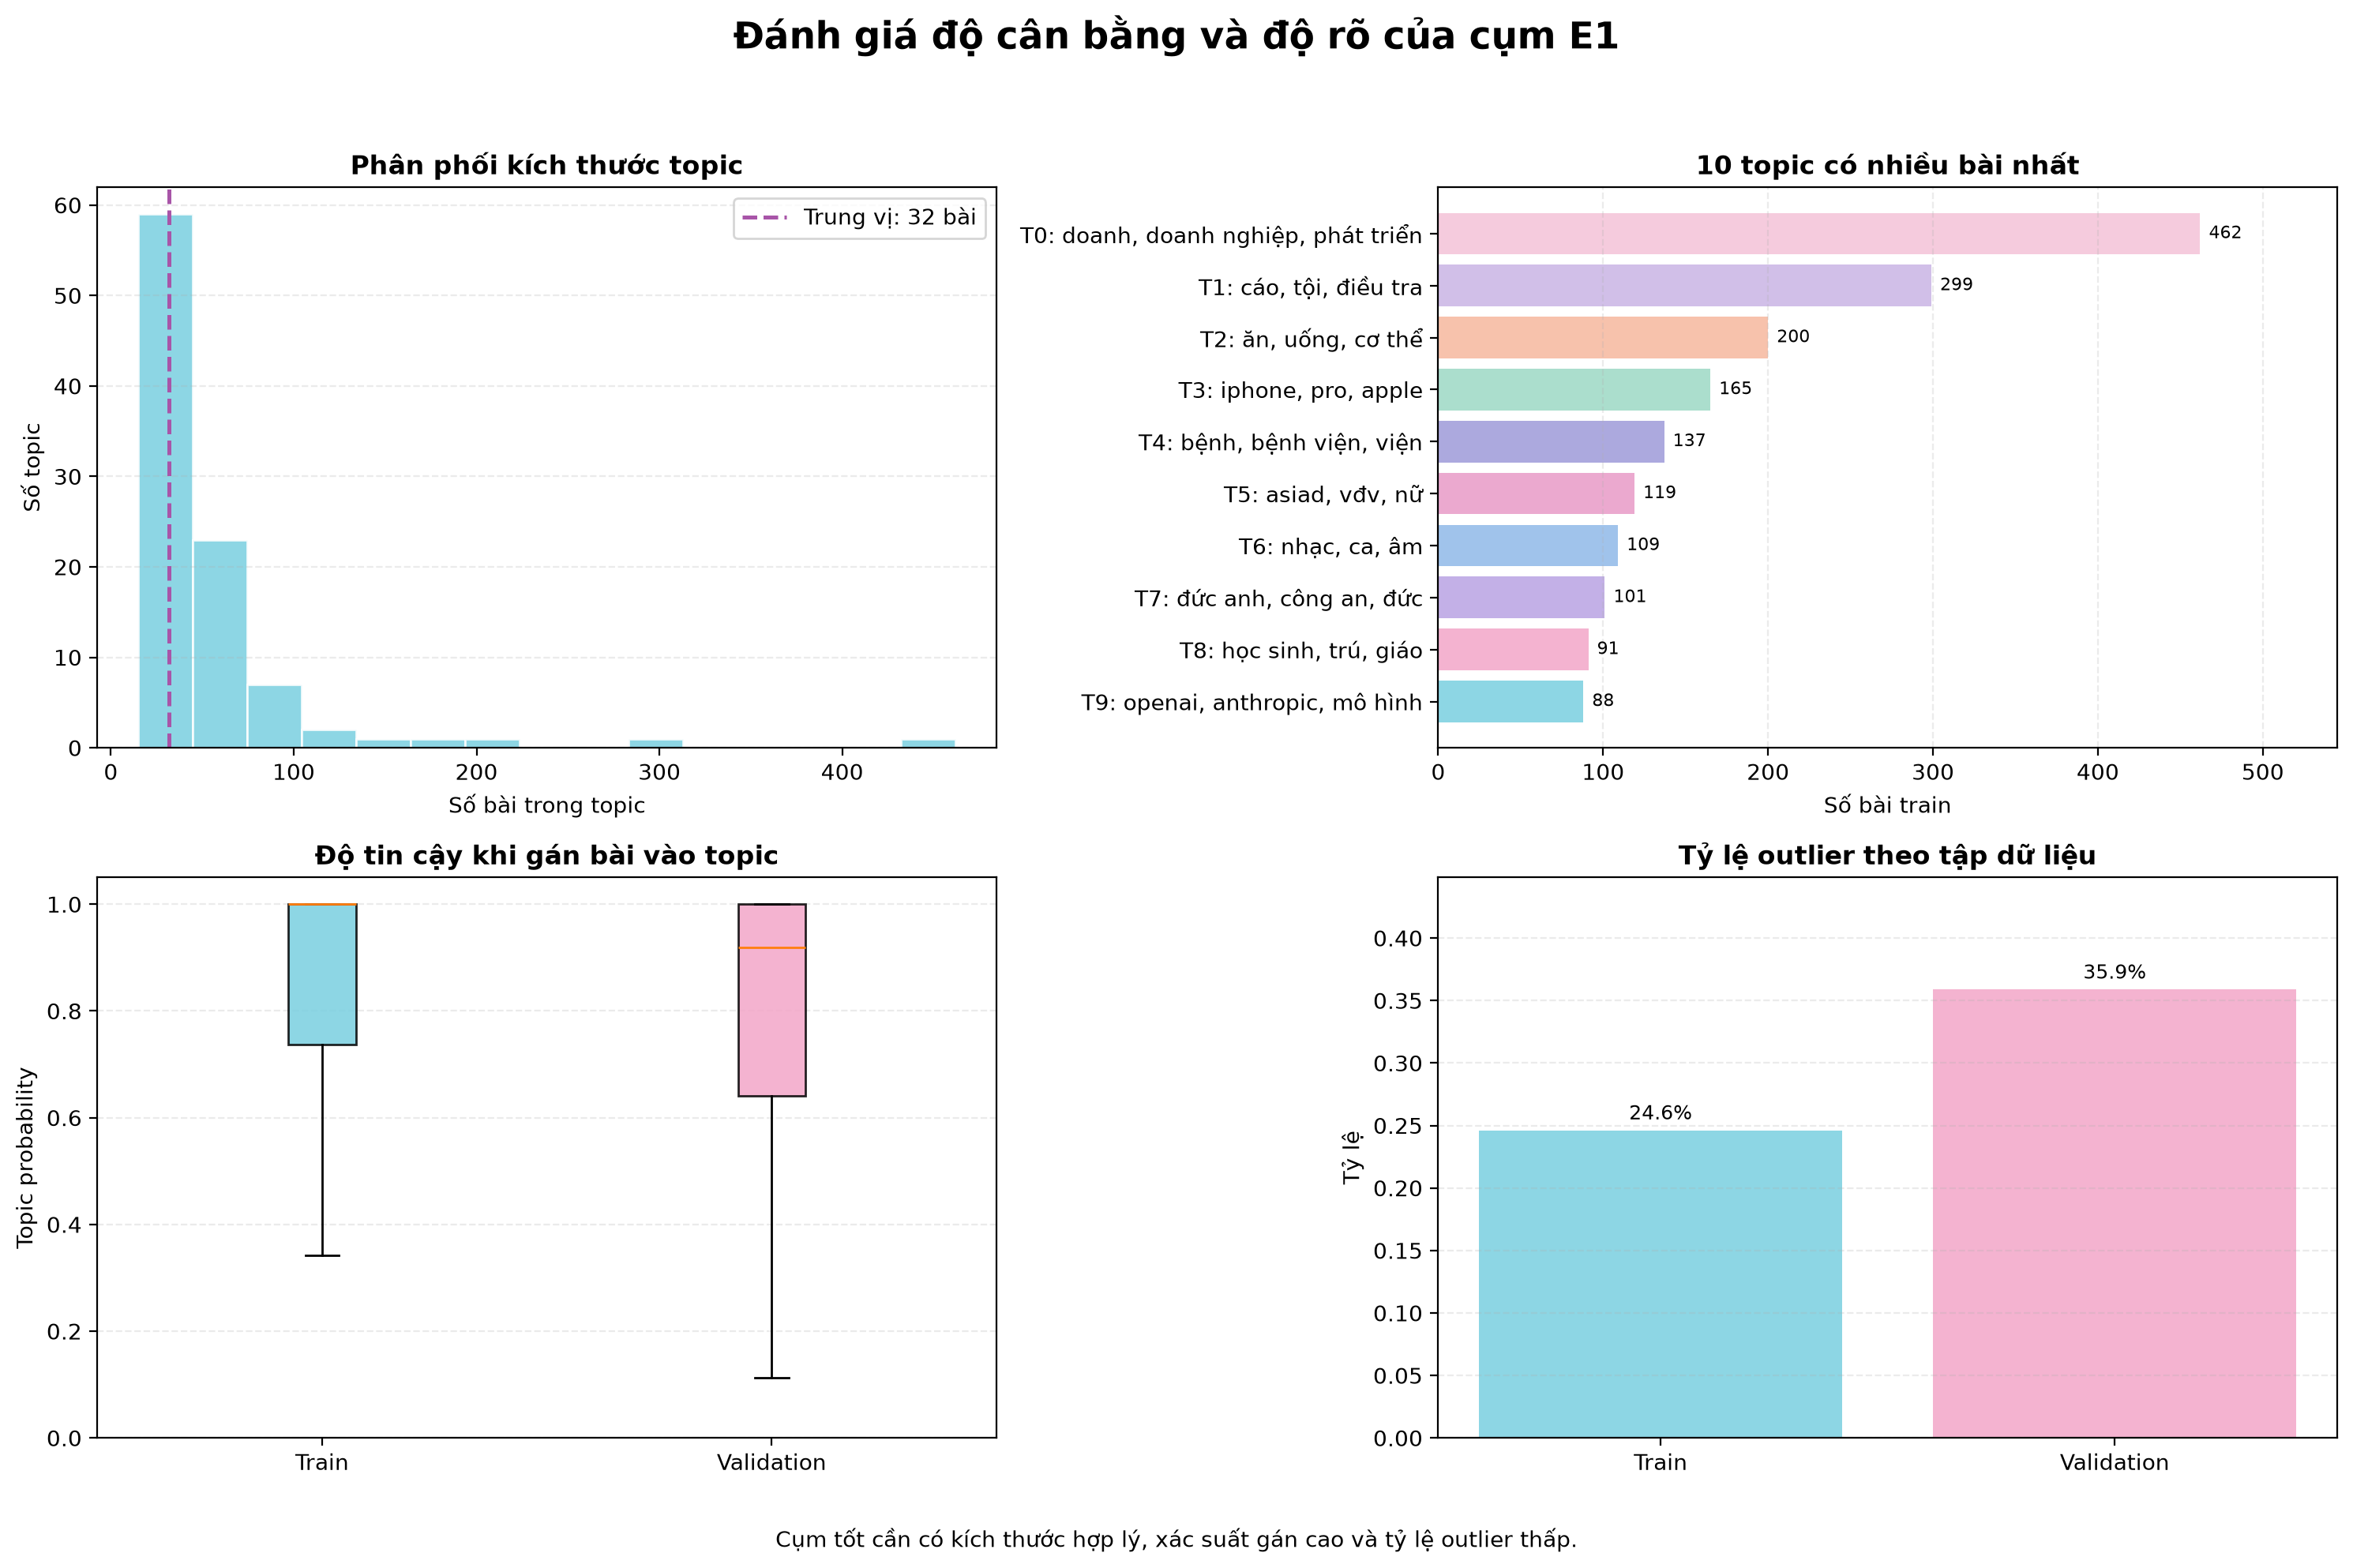

In [12]:
display(Image(filename=str(FIGURE_DIR / "08_e1_cluster_evaluation.png")))

## 9. Kết luận

- Pipeline đã hoàn thành luồng embedding → UMAP → HDBSCAN → c-TF-IDF.
- E1 tạo 96 topic và có outlier thấp nhất trong bốn cấu hình được thử.
- Nhiều topic có nội dung rõ như pháp luật, sức khỏe, công nghệ, thể thao và giáo dục.
- E1 không tối ưu ở mọi tiêu chí: thời gian chạy cao và topic diversity thấp hơn E3.
- Outlier validation vẫn đáng kể, vì vậy cần tiếp tục cải thiện embedding, tiền xử lý hoặc tham số phân cụm.

### Hướng cải tiến

- bổ sung topic coherence;
- kiểm tra thủ công mẫu bài trong mỗi topic;
- thử thêm embedding và tham số UMAP/HDBSCAN;
- cải thiện tách từ và chuẩn hóa cụm từ tiếng Việt;
- chỉ sử dụng tập test một lần sau khi chốt cấu hình bằng validation.